In [1]:
# 导包
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# 1.加载数据
df_video = pd.read_csv('../../data/hot_video.csv')
df_comments = pd.read_csv('../../data/hot_comments_anonymized.csv')

In [3]:
# 2.视频数据概览
print('视频数据前5行：')
df_video.head()

视频数据前5行：


,aid,bvid,标题,分区,up主,播放,点赞,硬币,收藏,分享,评论数,说明
0,898762590,BV1MN4y177PB,回村三天，二舅治好了我的精神内耗,日常,衣戈猜想,58639796,6396775,7513841,2643966,2533947,68225,全网刷屏！治愈千万人的精神内耗
1,931463745,BV1AM4y1M71p,破亿纪念!【猛男版】新宝岛 4K高清重置加强版,舞蹈综合,猛男舞团IconX,54523272,3340439,1770799,1138746,632810,49616,镇站之宝《新宝岛》高清重制版
2,497651138,BV1BK411L7DJ,【罗翔】我们为什么要读书？,社科·法律·心理,罗翔说刑法,23334888,1486734,1019862,817537,354387,33807,引发全站思考，共同探讨读书的意义
3,339882689,BV1dR4y1F7Aq,⚡️ 中 国 人 不 蹦 洋 迪 ⚡️,MAD·AMV,钓可尔太曼,45911296,3304086,1824491,1295721,363278,34623,彰显中式美学魅力的国产动画剪辑佳作
4,615209469,BV1ph4y1g75E,火柴人 VS 数学(Math),同人·手书,火柴人AlanBecker,36338415,2466691,1932463,1763548,675263,31086,史上最难看懂的数学动画神作


In [4]:
print('视频数据信息：')
df_video.info()

视频数据信息：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   aid     98 non-null     int64 
 1   bvid    98 non-null     object
 2   标题      98 non-null     object
 3   分区      98 non-null     object
 4   up主     98 non-null     object
 5   播放      98 non-null     int64 
 6   点赞      98 non-null     int64 
 7   硬币      98 non-null     int64 
 8   收藏      98 non-null     int64 
 9   分享      98 non-null     int64 
 10  评论数     98 non-null     int64 
 11  说明      98 non-null     object
dtypes: int64(7), object(5)
memory usage: 9.3+ KB


In [5]:
print('视频数据描述性统计：')
df_video.describe()

视频数据描述性统计：


,aid,播放,点赞,硬币,收藏,分享,评论数
count,9.800000e+01,9.800000e+01,9.800000e+01,9.800000e+01,9.800000e+01,9.800000e+01,98.000000
mean,2.002548e+08,2.355696e+07,1.190445e+06,1.040702e+06,6.777969e+05,2.474376e+05,59753.653061
std,2.958827e+08,2.338355e+07,1.267756e+06,1.258374e+06,6.576003e+05,3.631401e+05,99367.415012
min,1.060000e+02,3.094121e+06,5.448300e+04,1.955200e+04,7.211000e+04,4.295000e+03,0.000000
25%,2.341276e+06,8.670136e+06,3.806738e+05,2.699228e+05,2.751460e+05,6.239275e+04,11618.750000
50%,2.702020e+07,1.620038e+07,7.930660e+05,6.478795e+05,4.996380e+05,1.367135e+05,22842.500000
75%,4.659426e+08,2.673991e+07,1.584844e+06,1.137526e+06,7.442940e+05,2.808752e+05,53734.750000
max,9.686868e+08,1.290010e+08,6.396775e+06,7.513841e+06,3.555612e+06,2.533947e+06,644946.000000


In [6]:
# 评论数据概览
print('评论数据前5行：')
df_comments.head()

评论数据前5行：


,bvid,用户名,用户id,等级,评论id,评论内容,点赞数
0,BV1MN4y177PB,用户0001,uid_0001,5,c_810b37fa110c,希望几年后有人能按这个按钮召唤我回来\n ...,7418
1,BV1MN4y177PB,用户0002,uid_0002,6,c_7dca6965abcc,这期视频的文案，真是看几遍也看不够的，愿称其为一种冷峻的幽默感。看似置身事外淡淡地叙述，偶有...,537204
2,BV1MN4y177PB,用户0003,uid_0003,4,c_410a6358eb16,这个故事在很多年以前看过，励志视频,0
3,BV1MN4y177PB,用户0004,uid_0004,5,c_da8ee3b0f995,2026年来考古，有人吗[doge]\n有人回一下[星星眼],7841
4,BV1MN4y177PB,用户0005,uid_0005,6,c_36aeb8742e94,都在歌颂二舅面对不幸时的坦然和坚持。可只有二舅知道这有多么的心酸和不宜。整个视频，他全程沉默...,411


In [7]:
print('评论数据信息：')
df_comments.info()

评论数据信息：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9700 entries, 0 to 9699
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   bvid    9700 non-null   object
 1   用户名     9700 non-null   object
 2   用户id    9700 non-null   object
 3   等级      9700 non-null   int64 
 4   评论id    9700 non-null   object
 5   评论内容    9700 non-null   object
 6   点赞数     9700 non-null   int64 
dtypes: int64(2), object(5)
memory usage: 530.6+ KB


In [8]:
print('评论数据描述性统计：')
df_comments.describe()

评论数据描述性统计：


,等级,点赞数
count,9700.000000,9700.000000
mean,5.617732,5098.365773
std,1.005324,23633.461071
min,0.000000,0.000000
25%,6.000000,33.000000
50%,6.000000,110.000000
75%,6.000000,943.250000
max,6.000000,693858.000000


In [9]:
# 3.数据清洗
# 检查是否有缺失值
df_video.isna().sum()

aid     0
bvid    0
标题      0
分区      0
up主     0
播放      0
点赞      0
硬币      0
收藏      0
分享      0
评论数     0
说明      0
dtype: int64

In [10]:
df_comments.isna().sum()

bvid    0
用户名     0
用户id    0
等级      0
评论id    0
评论内容    0
点赞数     0
dtype: int64

In [11]:
# 检查是否有重复值
df_video.duplicated().sum()

np.int64(0)

In [12]:
df_comments.duplicated().sum()

np.int64(0)

In [13]:
# 异常值的处理
# 对评论数据进行筛选，保留点赞数≥10、文本长度大于5的有效评论，过滤低质量短评论与水评
df_comments_clean = df_comments[(df_comments['点赞数'] >= 10) & (df_comments['评论内容'].str.len() > 5)]
print(f'原始评论数：{len(df_comments)}，过滤后：{len(df_comments_clean)}')

原始评论数：9700，过滤后：9090


In [14]:
# 4.新数据特征构造
df_video['点赞率'] = df_video['点赞'] / df_video['播放']
df_video['投币率'] = df_video['硬币'] / df_video['播放']
df_video['收藏率'] = df_video['收藏'] / df_video['播放']
df_video['转发率'] = df_video['分享'] / df_video['播放']
df_video['评论率'] = df_video['评论数'] / df_video['播放']
df_video.head()

,aid,bvid,标题,分区,up主,播放,点赞,硬币,收藏,分享,评论数,说明,点赞率,投币率,收藏率,转发率,评论率
0,898762590,BV1MN4y177PB,回村三天，二舅治好了我的精神内耗,日常,衣戈猜想,58639796,6396775,7513841,2643966,2533947,68225,全网刷屏！治愈千万人的精神内耗,0.109086,0.128136,0.045088,0.043212,0.001163
1,931463745,BV1AM4y1M71p,破亿纪念!【猛男版】新宝岛 4K高清重置加强版,舞蹈综合,猛男舞团IconX,54523272,3340439,1770799,1138746,632810,49616,镇站之宝《新宝岛》高清重制版,0.061266,0.032478,0.020886,0.011606,0.000910
2,497651138,BV1BK411L7DJ,【罗翔】我们为什么要读书？,社科·法律·心理,罗翔说刑法,23334888,1486734,1019862,817537,354387,33807,引发全站思考，共同探讨读书的意义,0.063713,0.043705,0.035035,0.015187,0.001449
3,339882689,BV1dR4y1F7Aq,⚡️ 中 国 人 不 蹦 洋 迪 ⚡️,MAD·AMV,钓可尔太曼,45911296,3304086,1824491,1295721,363278,34623,彰显中式美学魅力的国产动画剪辑佳作,0.071967,0.039739,0.028222,0.007913,0.000754
4,615209469,BV1ph4y1g75E,火柴人 VS 数学(Math),同人·手书,火柴人AlanBecker,36338415,2466691,1932463,1763548,675263,31086,史上最难看懂的数学动画神作,0.067881,0.053180,0.048531,0.018583,0.000855


In [15]:
# 从评论表提取视频级别的特征
comment_features = df_comments.groupby('bvid').agg(
    平均评论点赞 = ('点赞数', 'mean'),
    最大评论点赞 = ('点赞数', 'max'),
    评论点赞标准差 = ('点赞数', 'std'),
    评论数_实际 = ('点赞数', 'count')
).reset_index()
comment_features

,bvid,平均评论点赞,最大评论点赞,评论点赞标准差,评论数_实际
0,BV11p411o73u,934.21,20759,2964.484023,100
1,BV12J411X7cD,2117.85,45934,6148.249573,100
2,BV12s411N7g2,930.74,39650,4390.453051,100
3,BV13X4y1P7z7,4416.25,123111,15553.158593,100
4,BV14U4y1w7fn,1029.43,34633,4475.919133,100
...,...,...,...,...,...
92,BV1xx411c7XW,4155.82,129330,17600.836695,100
93,BV1xx411c7mu,11499.55,271656,31954.416733,100
94,BV1yt4y1Q7SS,13952.44,301440,42762.527018,100
95,BV1zp4y1U7Z5,4261.12,79299,13797.871818,100


In [16]:
# 合并
df_video = pd.merge(df_video, comment_features, on='bvid', how='left')
df_video

,aid,bvid,标题,分区,up主,播放,点赞,硬币,收藏,分享,...,说明,点赞率,投币率,收藏率,转发率,评论率,平均评论点赞,最大评论点赞,评论点赞标准差,评论数_实际
0,898762590,BV1MN4y177PB,回村三天，二舅治好了我的精神内耗,日常,衣戈猜想,58639796,6396775,7513841,2643966,2533947,...,全网刷屏！治愈千万人的精神内耗,0.109086,0.128136,0.045088,0.043212,0.001163,18685.33,537204.0,68869.044547,100.0
1,931463745,BV1AM4y1M71p,破亿纪念!【猛男版】新宝岛 4K高清重置加强版,舞蹈综合,猛男舞团IconX,54523272,3340439,1770799,1138746,632810,...,镇站之宝《新宝岛》高清重制版,0.061266,0.032478,0.020886,0.011606,0.000910,13309.30,243463.0,37340.207938,100.0
2,497651138,BV1BK411L7DJ,【罗翔】我们为什么要读书？,社科·法律·心理,罗翔说刑法,23334888,1486734,1019862,817537,354387,...,引发全站思考，共同探讨读书的意义,0.063713,0.043705,0.035035,0.015187,0.001449,6617.67,98766.0,17949.102678,100.0
3,339882689,BV1dR4y1F7Aq,⚡️ 中 国 人 不 蹦 洋 迪 ⚡️,MAD·AMV,钓可尔太曼,45911296,3304086,1824491,1295721,363278,...,彰显中式美学魅力的国产动画剪辑佳作,0.071967,0.039739,0.028222,0.007913,0.000754,8582.25,451117.0,47881.620857,100.0
4,615209469,BV1ph4y1g75E,火柴人 VS 数学(Math),同人·手书,火柴人AlanBecker,36338415,2466691,1932463,1763548,675263,...,史上最难看懂的数学动画神作,0.067881,0.053180,0.048531,0.018583,0.000855,6512.12,235984.0,26237.417039,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,8506694,BV1Sx41117dD,【2017拜年祭单品】万神纪【星尘原创曲】,VOCALOID·UTAU,写歌的海鲜面,8536651,217814,285252,352090,49467,...,「2017哔哩哔哩音乐大赏」获奖作品,0.025515,0.033415,0.041245,0.005795,0.007786,1863.83,58789.0,7872.160713,100.0
94,1638627,BV1tx411P7N4,冰雪奇缘X守护者联盟【误解向】Frozen Guardian,影视剪辑,时海,4643735,174761,146502,237253,53307,...,误解系混剪视频的巅峰,0.037634,0.031548,0.051091,0.011479,0.002635,1721.42,44121.0,6026.012981,100.0
95,5512579,BV1fs411k7Kj,感觉身体被掏空by彩虹室内合唱团,原创音乐,上海彩虹室内合唱团,4894176,61720,89198,85609,60779,...,2016年度神曲，彩虹室内合唱团成名作之一,0.012611,0.018225,0.017492,0.012419,0.000987,570.78,12481.0,1938.344157,100.0
96,1252354,BV1Sx411T7L3,【世界版】Blessing【原创PV】,翻唱,茶理理理子,7728377,274156,304264,437944,61953,...,13国歌手合唱，献给世界和平的音乐合作企划,0.035474,0.039370,0.056667,0.008016,0.003230,1820.21,30937.0,4855.254318,100.0


In [17]:
# 播放量分箱
df_video['播放量级别'] = pd.qcut(df_video['播放'], q=3, labels=['低播放', '中播放', '高播放'])
df_video

,aid,bvid,标题,分区,up主,播放,点赞,硬币,收藏,分享,...,点赞率,投币率,收藏率,转发率,评论率,平均评论点赞,最大评论点赞,评论点赞标准差,评论数_实际,播放量级别
0,898762590,BV1MN4y177PB,回村三天，二舅治好了我的精神内耗,日常,衣戈猜想,58639796,6396775,7513841,2643966,2533947,...,0.109086,0.128136,0.045088,0.043212,0.001163,18685.33,537204.0,68869.044547,100.0,高播放
1,931463745,BV1AM4y1M71p,破亿纪念!【猛男版】新宝岛 4K高清重置加强版,舞蹈综合,猛男舞团IconX,54523272,3340439,1770799,1138746,632810,...,0.061266,0.032478,0.020886,0.011606,0.000910,13309.30,243463.0,37340.207938,100.0,高播放
2,497651138,BV1BK411L7DJ,【罗翔】我们为什么要读书？,社科·法律·心理,罗翔说刑法,23334888,1486734,1019862,817537,354387,...,0.063713,0.043705,0.035035,0.015187,0.001449,6617.67,98766.0,17949.102678,100.0,中播放
3,339882689,BV1dR4y1F7Aq,⚡️ 中 国 人 不 蹦 洋 迪 ⚡️,MAD·AMV,钓可尔太曼,45911296,3304086,1824491,1295721,363278,...,0.071967,0.039739,0.028222,0.007913,0.000754,8582.25,451117.0,47881.620857,100.0,高播放
4,615209469,BV1ph4y1g75E,火柴人 VS 数学(Math),同人·手书,火柴人AlanBecker,36338415,2466691,1932463,1763548,675263,...,0.067881,0.053180,0.048531,0.018583,0.000855,6512.12,235984.0,26237.417039,100.0,高播放
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,8506694,BV1Sx41117dD,【2017拜年祭单品】万神纪【星尘原创曲】,VOCALOID·UTAU,写歌的海鲜面,8536651,217814,285252,352090,49467,...,0.025515,0.033415,0.041245,0.005795,0.007786,1863.83,58789.0,7872.160713,100.0,低播放
94,1638627,BV1tx411P7N4,冰雪奇缘X守护者联盟【误解向】Frozen Guardian,影视剪辑,时海,4643735,174761,146502,237253,53307,...,0.037634,0.031548,0.051091,0.011479,0.002635,1721.42,44121.0,6026.012981,100.0,低播放
95,5512579,BV1fs411k7Kj,感觉身体被掏空by彩虹室内合唱团,原创音乐,上海彩虹室内合唱团,4894176,61720,89198,85609,60779,...,0.012611,0.018225,0.017492,0.012419,0.000987,570.78,12481.0,1938.344157,100.0,低播放
96,1252354,BV1Sx411T7L3,【世界版】Blessing【原创PV】,翻唱,茶理理理子,7728377,274156,304264,437944,61953,...,0.035474,0.039370,0.056667,0.008016,0.003230,1820.21,30937.0,4855.254318,100.0,低播放


In [18]:
# 5.保存文件
df_video.to_csv('../../data/hot_video_processed.csv',index=False, encoding='utf-8-sig')
df_comments_clean.to_csv('../../data/hot_comments_clean_anonymized.csv',index=False, encoding='utf-8-sig')

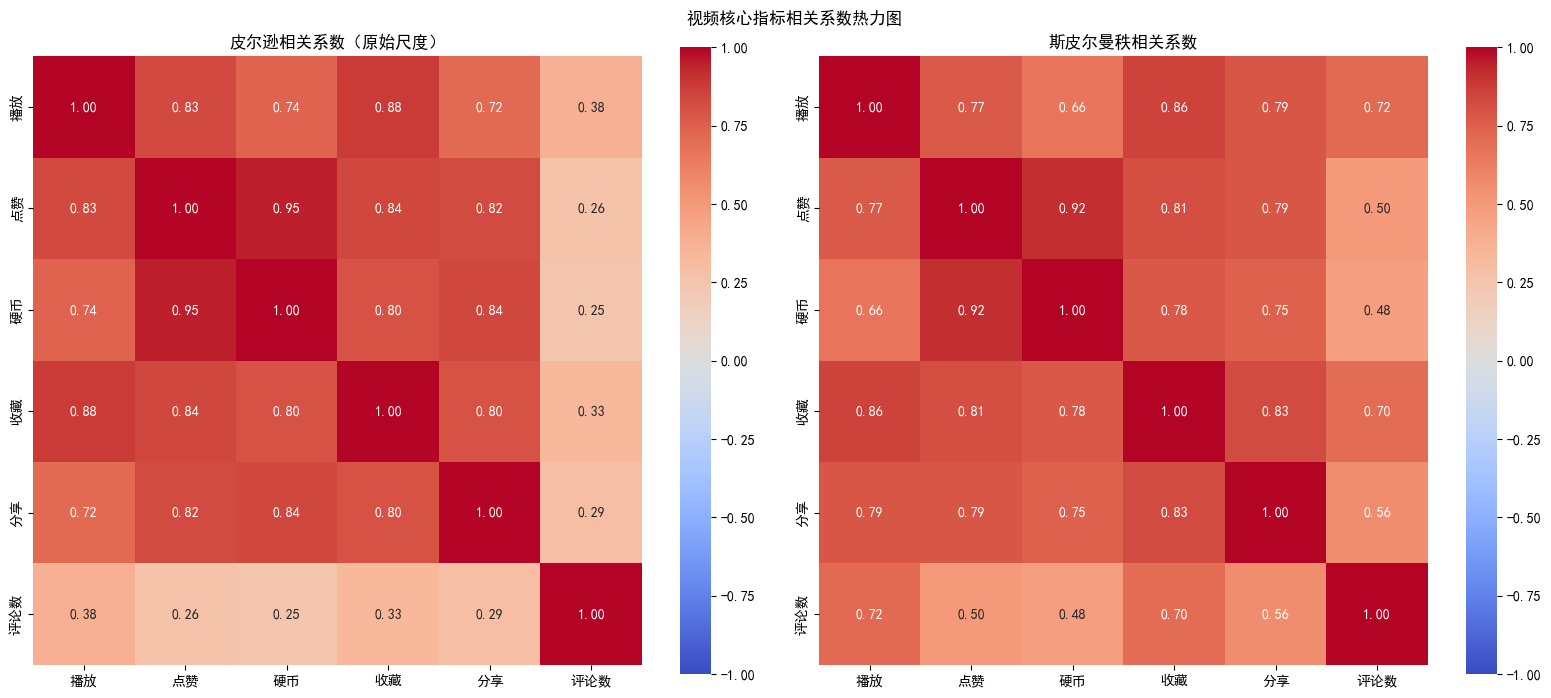

In [19]:
# 6.数据可视化
# 6.1相关系数热力图：左图是原始尺度的皮尔逊相关，右图是斯皮尔曼秩相关
corr_cols = ['播放', '点赞', '硬币', '收藏', '分享', '评论数']
corr_pearson = df_video[corr_cols].corr()
corr_spearman = df_video[corr_cols].corr(method='spearman')
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, corr, title in zip(axes, [corr_pearson, corr_spearman],
                           ['皮尔逊相关系数（原始尺度）', '斯皮尔曼秩相关系数']):
    sns.heatmap(corr, ax=ax, cmap='coolwarm', vmin=-1, vmax=1, center=0,
                annot=True, fmt='.2f', square=True)
    ax.set_title(title)
plt.suptitle('视频核心指标相关系数热力图')
plt.tight_layout()
plt.savefig('../../data/fig/analysis/视频核心指标相关系数热力图.png')
plt.show()

# 视频核心指标相关系数热力图

图表信息：左图为播放、点赞、硬币、收藏、分享、评论数的皮尔逊相关系数（原始尺度），右图为斯皮尔曼秩相关系数；两张图统一使用 -1～1 的固定色标（红=正相关，蓝=负相关），并标注具体数值。

解读：
1. 播放、点赞、硬币、收藏、分享之间高度正相关（皮尔逊 0.72～0.95），播放越高的视频，点赞、投币、收藏、转发一般同步上涨；其中点赞与硬币相关最强（0.95），说明「点赞 + 投币」往往是同一批用户的高频组合；
2. 评论数与其余指标的皮尔逊相关明显偏低（0.25～0.38），单看左图很容易得出「高播放不一定带来评论增长、评论的驱动逻辑不同」；
3. 但换成秩相关后评论数并不弱：与播放 0.72、与收藏 0.70、与分享 0.56，都远高于皮尔逊系数。原因是播放量本身右偏严重（偏度 2.48），少数超高播放视频把皮尔逊系数压低了。更稳妥的结论是「评论数的增长幅度小于点赞投币，而不是评论与流量无关」；分析这类偏态指标时应优先看秩相关，或先做对数变换再看皮尔逊。

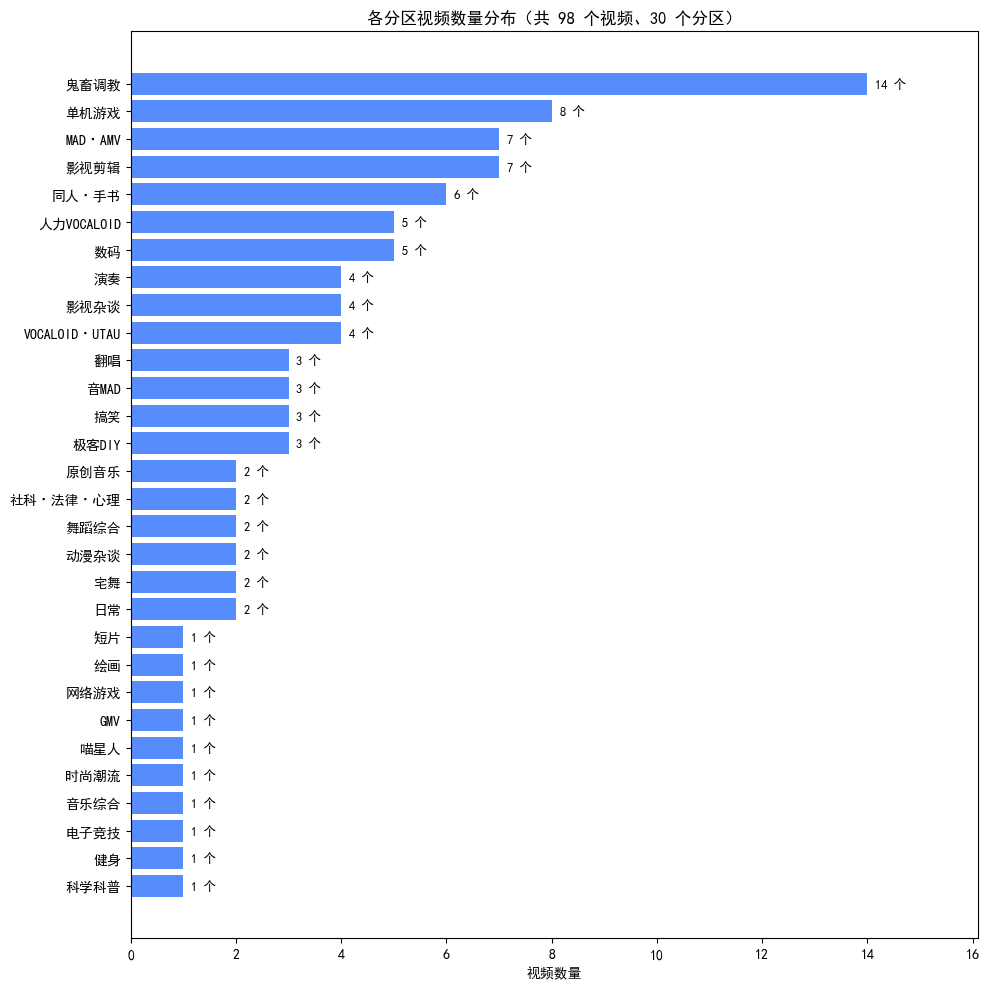

In [20]:
# 6.2各分区视频数量分布：共 30 个分区，用横向条形图才放得下分区名，并直接标出数量
tname_counts = df_video['分区'].value_counts().sort_values()
y = np.arange(len(tname_counts))
plt.figure(figsize=(10, 10))
plt.barh(y, tname_counts.values)
for i, value in enumerate(tname_counts.values):
    plt.text(value + 0.15, y[i], f'{value} 个', va='center', fontsize=9)
plt.yticks(y, tname_counts.index)
plt.xlim(0, tname_counts.max() * 1.15)
plt.title(f'各分区视频数量分布（共 {len(df_video)} 个视频、{len(tname_counts)} 个分区）')
plt.xlabel('视频数量')
plt.tight_layout()
plt.savefig('../../data/fig/analysis/各分区视频数量分布.png')
plt.show()

# 各分区视频数量分布条形图

图表信息：纵轴分区（按视频数量升序排列），横轴样本视频数量，柱子右侧标注具体数量。

解读：
1. 样本采集明显不均衡：鬼畜调教最多（14 个），其次是单机游戏（8 个）、影视剪辑与 MAD·AMV（各 7 个）、同人·手书（6 个）、数码与人力 VOCALOID（各 5 个）；
2. 30 个分区里只有 7 个样本量 ≥5，另有 10 个分区只有 1 个视频，平均每个分区不到 3.3 个视频；
3. 因此后面所有按分区比较的图都只保留样本量 ≥5 的分区——否则单个视频就会变成一个「分区结论」；样本量小的分区只能当线索，不能当结论。

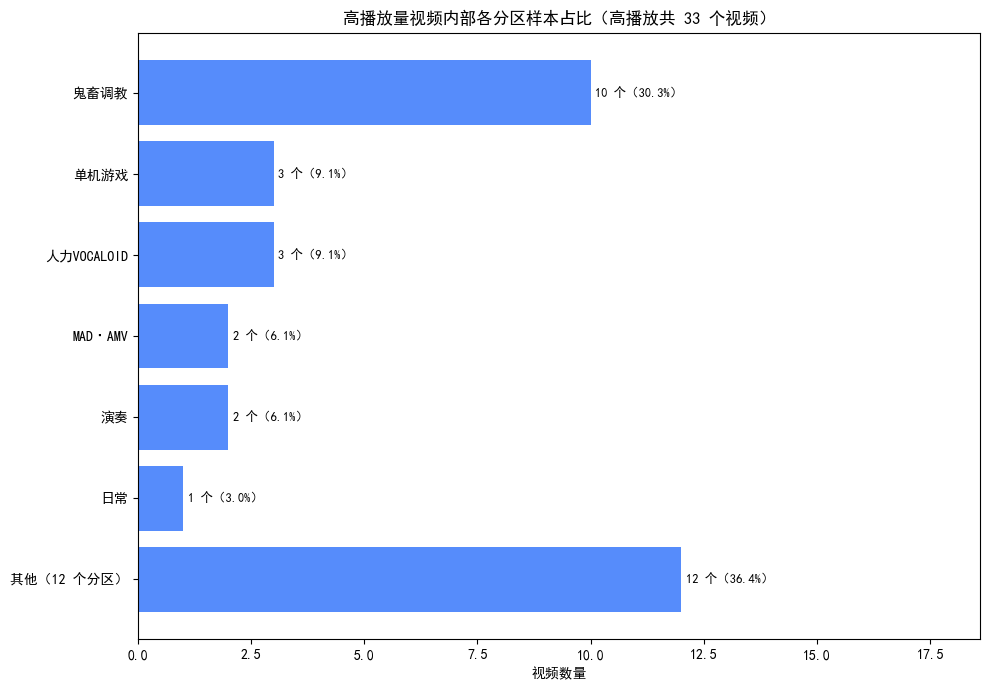

In [21]:
# 6.3高播放子集的分区构成：高播放共 33 个视频，却分散在 18 个分区里，
# 直接画饼图最小切片只有 1 个视频（3.0%），这里改成条形图，只画前 6 名，其余合并成「其他」放最下面
high_play = df_video[df_video['播放量级别'] == '高播放']
high_tname_counts = high_play['分区'].value_counts()
top6 = high_tname_counts.head(6).sort_values()
names = [f'其他（{len(high_tname_counts) - 6} 个分区）'] + list(top6.index)
values = [high_tname_counts.iloc[6:].sum()] + list(top6.values)
y = np.arange(len(names))
plt.figure(figsize=(10, 7))
plt.barh(y, values)
for i, value in enumerate(values):
    plt.text(value + 0.1, y[i], f'{value} 个（{value / len(high_play) * 100:.1f}%）', va='center', fontsize=9)
plt.yticks(y, names)
plt.xlim(0, max(values) * 1.55)
plt.title(f'高播放量视频内部各分区样本占比（高播放共 {len(high_play)} 个视频）')
plt.xlabel('视频数量')
plt.tight_layout()
plt.savefig('../../data/fig/analysis/高播放量视频内部各分区样本占比.png')
plt.show()

# 高播放量视频内部各分区样本占比条形图

图表信息：仅筛选高播放子集（33 个视频），横轴视频数量，柱子右侧同时标注数量与在子集中的占比；只展示前 6 个分区，其余 12 个分区合并为「其他」。

解读：
1. 鬼畜调教占比最高：10 个视频，占高播放子集的 30.3%，是产出爆款最多的分区；
2. 第二梯队是人力 VOCALOID 与单机游戏各 3 个（9.1%），第三梯队是演奏与 MAD·AMV 各 2 个（6.1%）；
3. 其余 12 个分区各只有 1 个视频（3.0%），说明「爆款出在哪个分区」本身相当分散，并没有被少数分区垄断；
4. 注意样本量：高播放子集只有 33 个视频，1 个视频就等于 3.0%，所以 2 个和 3 个之间的差距不宜过度解读；能站得住的结论只有「鬼畜调教明显最多」。

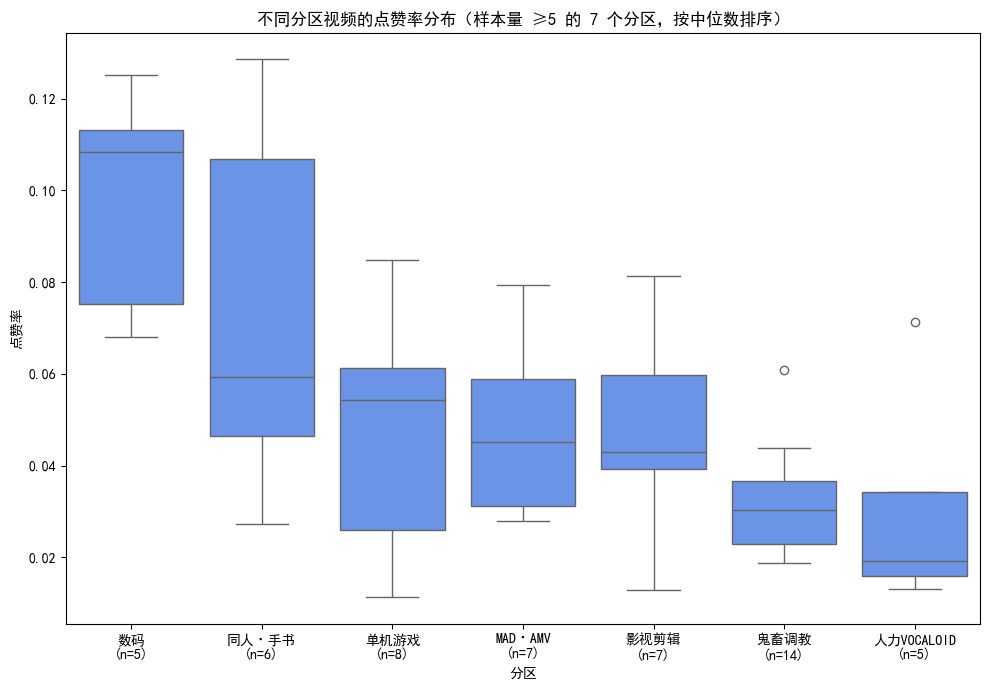

In [22]:
# 6.4不同分区视频的点赞率分布：只保留样本量 ≥5 的 7 个分区，按点赞率中位数从高到低排序，
part_count = df_video['分区'].value_counts()
big_part = part_count[part_count >= 5].index
part_median = df_video[df_video['分区'].isin(big_part)].groupby('分区')['点赞率'].median()
part_order = part_median.sort_values(ascending=False).index
plt.figure(figsize=(10, 7))
sns.boxplot(x='分区', y='点赞率', data=df_video[df_video['分区'].isin(big_part)], order=part_order)
plt.xticks(range(len(part_order)), [f'{name}\n(n={part_count[name]})' for name in part_order])
plt.ylabel('点赞率')
plt.title('不同分区视频的点赞率分布（样本量 ≥5 的 7 个分区，按中位数排序）')
plt.tight_layout()
plt.savefig('../../data/fig/analysis/不同分区视频的点赞率分布.png')
plt.show()

# 不同分区视频的点赞率分布箱线图

图表信息：横轴为样本量 ≥5 的 7 个分区（按点赞率中位数从高到低排列，括号内为该分区的视频数），纵轴点赞率；箱体表示四分位数，上下须是取值范围，圆点是异常值。

解读：
1. 样本量足够的 7 个分区里，数码分区点赞率中位数最高（0.108），其次是同人·手书（0.059）、单机游戏（0.054）、MAD·AMV（0.045）、影视剪辑（0.043），鬼畜调教（0.030）与人力 VOCALOID（0.019）偏低，最高与最低相差约 5.7 倍；
2. 同一分区内部差异同样很大：MAD·AMV、鬼畜调教的箱体很长，既有高点赞率作品也有低点赞率作品，说明分区题材只解释一部分差异，单条视频的完成质量影响更大；
3. 日常分区的点赞率中位数虽然最高（0.133），但只有 2 个样本，不纳入结论；类似地，网络上常见的「网络游戏、GMV 分区点赞率整体偏低」在本数据里各只有 1 个视频，无法支撑。

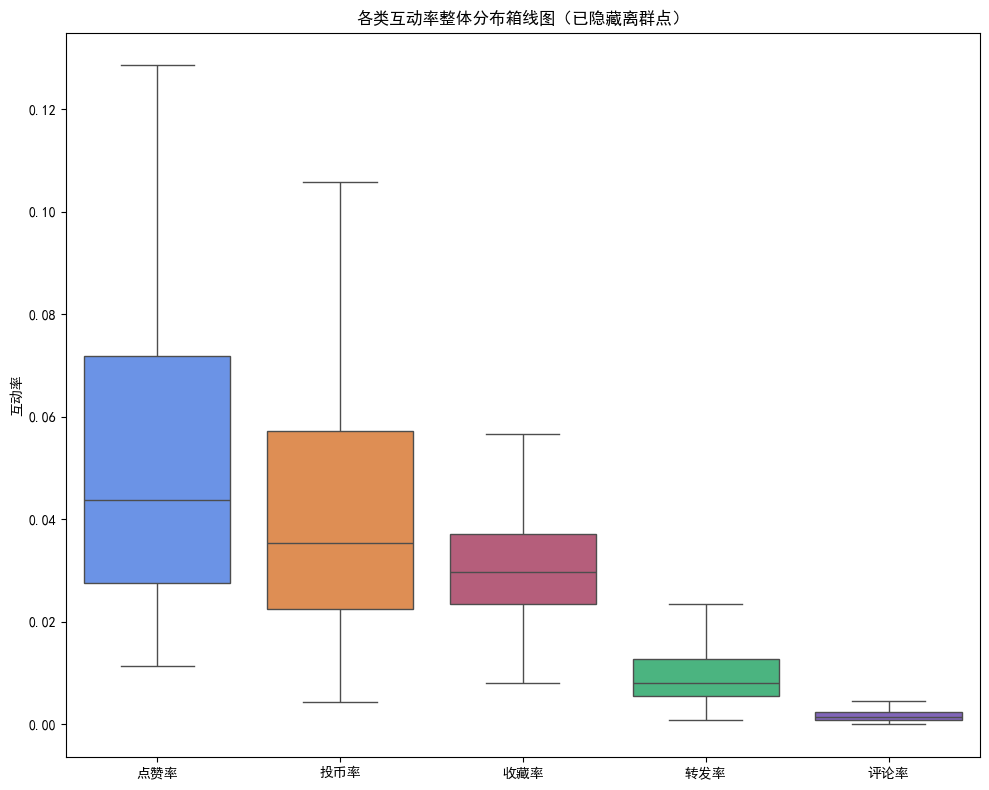

In [23]:
# 6.5各类互动率整体分布：投币率最大值 0.258，是中位数（0.035）的 7 倍多，
rate_df = df_video[['点赞率', '投币率', '收藏率', '转发率', '评论率']]
plt.figure(figsize=(10, 8))
sns.boxplot(data=rate_df, showfliers=False)
plt.ylabel('互动率')
plt.title('各类互动率整体分布箱线图（已隐藏离群点）')
plt.tight_layout()
plt.savefig('../../data/fig/analysis/各类互动率整体分布.png')
plt.show()

# 各类互动率整体分布箱线图

图表信息：5 类互动指标（点赞率、投币率、收藏率、转发率、评论率），为保证箱体形状看得清，已隐藏离群点；其中评论率整体数值极小（中位数 0.0014），在图上接近一条线，读数请结合文字里的具体数值。

解读：
1. 中位数排序：点赞率（0.0438）＞投币率（0.0354）＞收藏率（0.0297）＞转发率（0.0080）＞评论率（0.0014），点赞是用户最容易完成的互动行为，评论率最低，说明发表评论的门槛最高；
2. 被隐藏的离群点同样值得关注：投币率最大值 0.258，是中位数的 7 倍多，少数视频的用户付费式互动意愿远高于整体水平；
3. 相对波动（四分位距 / 中位数）较大的是点赞率（1.01）与评论率（1.01），两者几乎相同，所以「点赞率波动最大」只在绝对区间的意义上成立，不能推广成「点赞行为最不稳定」。

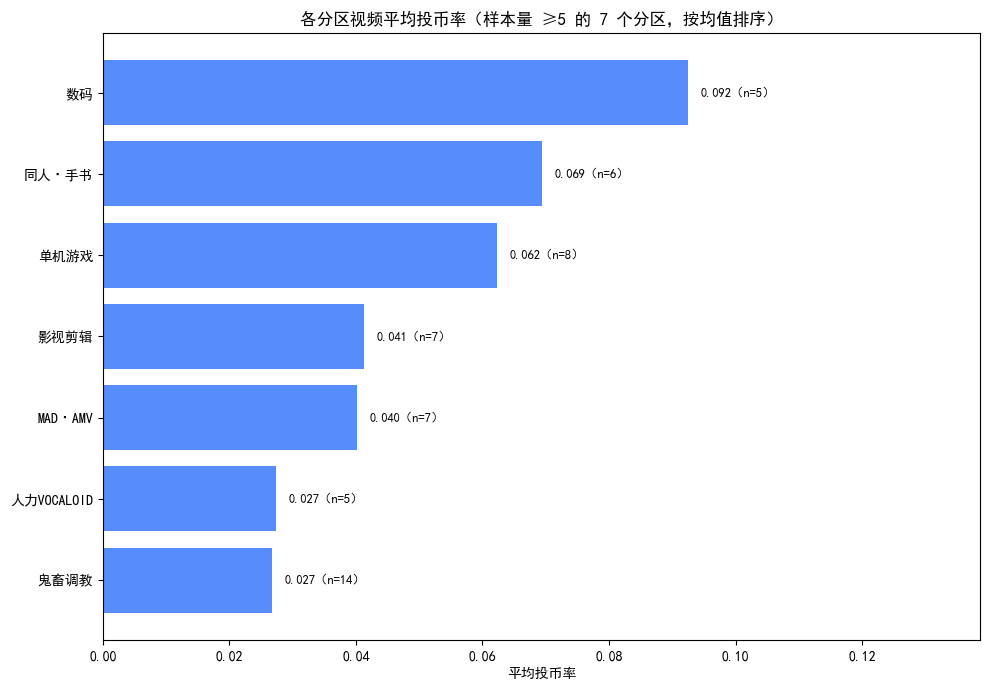

In [24]:
# 6.6各分区视频平均投币率：分区之间没有先后顺序，用折线连接会暗示出不存在的趋势，
part_count = df_video['分区'].value_counts()
big_part = part_count[part_count >= 5].index
coin_mean = df_video[df_video['分区'].isin(big_part)].groupby('分区')['投币率'].agg(['mean', 'count']).sort_values('mean')
y = np.arange(len(coin_mean))
plt.figure(figsize=(10, 7))
plt.barh(y, coin_mean['mean'])
for i, (mean, count) in enumerate(zip(coin_mean['mean'], coin_mean['count'])):
    plt.text(mean + 0.002, y[i], f'{mean:.3f}（n={int(count)}）', va='center', fontsize=9)
plt.yticks(y, coin_mean.index)
plt.xlim(0, coin_mean['mean'].max() * 1.5)
plt.xlabel('平均投币率')
plt.title('各分区视频平均投币率（样本量 ≥5 的 7 个分区，按均值排序）')
plt.tight_layout()
plt.savefig('../../data/fig/analysis/各分区视频平均投币率.png')
plt.show()

# 各分区视频平均投币率条形图

图表信息：纵轴为样本量 ≥5 的 7 个分区（按平均投币率升序排列，括号内为样本量），横轴平均投币率；「其他」类不在本图内，长尾分区因样本不足已剔除。原图是折线图，但分区之间没有先后顺序，折线会暗示出不存在的趋势，因此改为条形图。

解读：
1. 样本量足够的 7 个分区里，数码分区平均投币率最高（0.092），其次是同人·手书（0.069）与单机游戏（0.062），影视剪辑（0.041）、MAD·AMV（0.040）居中，人力 VOCALOID 与鬼畜调教最低（各 0.027），最高与最低相差 3.4 倍；
2. 差距确实存在，但并没有到「断层」的程度：前两名与后两名之间相差 2～3 倍，说明用户「愿意为哪类内容付费投币」有偏好，但不同分区之间仍有相当的重叠；
3. 日常分区看似断层第一（0.174 平均投币率），但只有 2 个视频，样本太少，不纳入结论；
4. 与点赞率对照看：数码分区两项都是第一；鬼畜调教视频最多（14 个），点赞率与投币率却都偏低（0.030 / 0.027），说明「看的人多」和「愿意点赞、投币」并不等同，投币的行为成本更高。

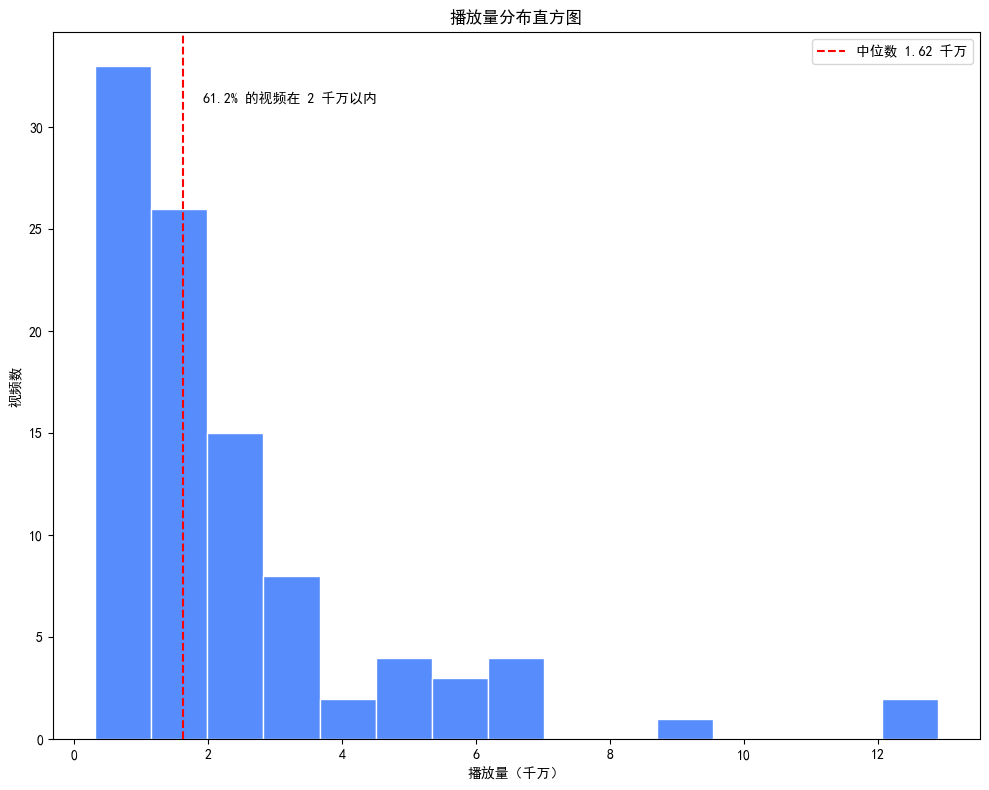

In [25]:
# 6.7播放量分布直方图：加一条中位数参考线，并在图上标出集中在低位区间的比例
plt.figure(figsize=(10, 8))
plt.hist(df_video['播放'] / 1e7, bins=15, edgecolor='white')
median_play = df_video['播放'].median() / 1e7
plt.axvline(median_play, color='red', linestyle='--', label=f'中位数 {median_play:.2f} 千万')
plt.text(median_play + 0.3, plt.ylim()[1] * 0.9,
         f'{(df_video["播放"] / 1e7 <= 2).mean() * 100:.1f}% 的视频在 2 千万以内', fontsize=10)
plt.xlabel('播放量（千万）')
plt.ylabel('视频数')
plt.title('播放量分布直方图')
plt.legend()
plt.tight_layout()
plt.savefig('../../data/fig/analysis/播放量分布直方图.png')
plt.show()

# 播放量分布直方图

图表信息：横轴播放量（千万），纵轴视频数量，红色虚线为中位数，图上标注了 2 千万以内的视频占比。

解读：
样本播放量呈现典型的长尾分布：播放量中位数 1.62 千万，61.2% 的视频集中在 2 千万以内，视频数量随播放量升高快速衰减；只有极少数突破 8 千万、12 千万（最高 12.9 千万），符合「少数爆款、多数普通」的流量特征。由于长尾明显（偏度 2.48），用均值代表整体水平会被少数爆款拉高，描述这类指标时中位数更有代表性。

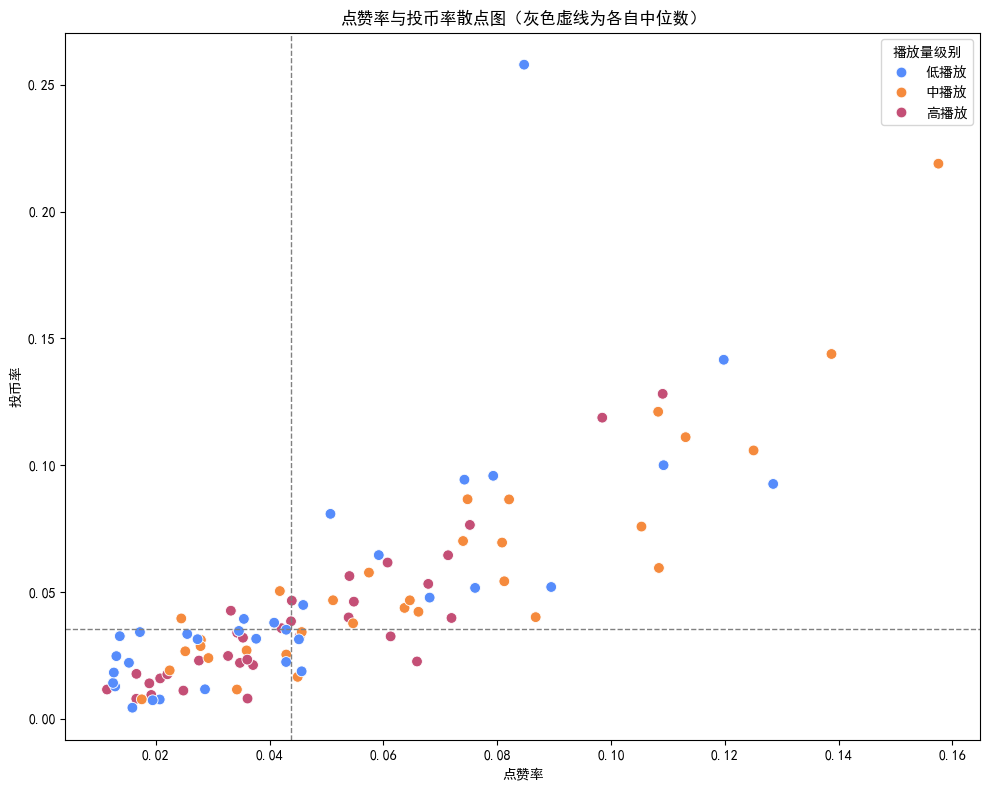

In [26]:
# 6.8点赞率与投币率散点图：两条虚线是各自的中位数，用来把「高互动区（右上角）」划分出来，
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df_video, x='点赞率', y='投币率', hue='播放量级别', s=60)
plt.axvline(df_video['点赞率'].median(), color='gray', linestyle='--', linewidth=1)
plt.axhline(df_video['投币率'].median(), color='gray', linestyle='--', linewidth=1)
plt.title('点赞率与投币率散点图（灰色虚线为各自中位数）')
plt.tight_layout()
plt.savefig('../../data/fig/analysis/点赞率与投币率散点图.png')
plt.show()

# 点赞率与投币率散点图

图表信息：横轴点赞率，纵轴投币率，颜色区分播放量级别（蓝=低播放、橙=中播放、绿=高播放），灰色虚线为两项指标各自的中位数，右上角即「双高互动」区域。

解读：
1. 点赞率与投币率明显正相关（皮尔逊 0.81、斯皮尔曼 0.86），点赞率高的视频投币率一般也高；
2. 但「播放越高互动越好」并不成立：落在右上角双高区域的视频占比是 中播放 59.4% ＞ 低播放 36.4% ＞ 高播放 33.3%，三组的点赞率中位数依次为 0.041 / 0.061 / 0.037，投币率中位数 0.034 / 0.045 / 0.033——互动率最高的是中播放，播放量到顶后反而回落到和低播放接近的水平；
3. 存在离群点：少量低播放视频也有极高的点赞率与投币率，说明播放量与互动质量不是一回事；
4. 需要留意口径：点赞率与投币率的分母都是播放量，两者正相关有一部分来自共同分母，不能直接理解成「点赞的人一定会投币」。

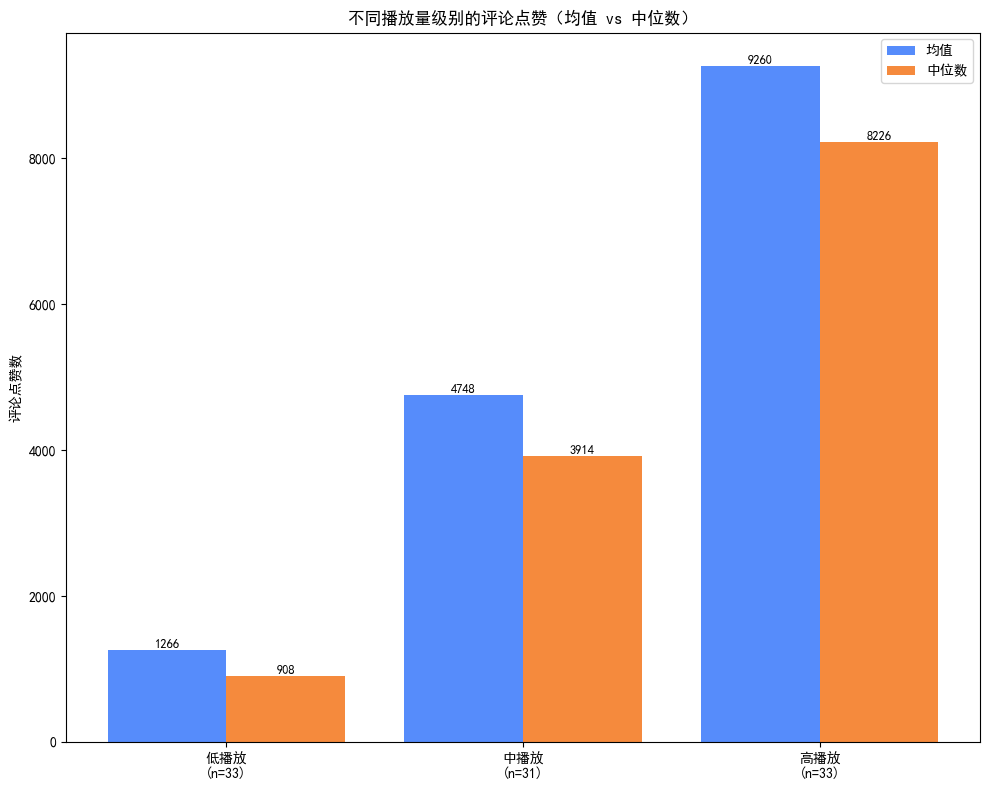

In [27]:
# 6.9各播放级别的评论点赞：评论点赞数右偏严重（单条最高 53.7 万），均值容易被极端值拉高，
stat = df_video.groupby('播放量级别', observed=False)['平均评论点赞'].agg(['mean', 'median', 'count']).reindex(['低播放', '中播放', '高播放'])
x = np.arange(len(stat))
plt.figure(figsize=(10, 8))
plt.bar(x - 0.2, stat['mean'], width=0.4, label='均值')
plt.bar(x + 0.2, stat['median'], width=0.4, label='中位数')
for i in range(len(stat)):
    plt.text(x[i] - 0.2, stat['mean'].iloc[i], f'{stat["mean"].iloc[i]:.0f}', ha='center', va='bottom', fontsize=9)
    plt.text(x[i] + 0.2, stat['median'].iloc[i], f'{stat["median"].iloc[i]:.0f}', ha='center', va='bottom', fontsize=9)
plt.xticks(x, [f'{name}\n(n={int(stat["count"].iloc[i])})' for i, name in enumerate(stat.index)])
plt.ylabel('评论点赞数')
plt.title('不同播放量级别的评论点赞（均值 vs 中位数）')
plt.legend()
plt.tight_layout()
plt.savefig('../../data/fig/analysis/不同播放量级别的平均评论点赞.png')
plt.show()

# 不同播放量级别的评论点赞柱状图（均值 vs 中位数）

图表信息：横轴为播放级别（低 / 中 / 高，括号内为该级别有评论数据的视频数），纵轴评论点赞数，同时给出均值与中位数。

解读：
1. 两个口径结论一致：播放量级别越高，评论点赞越高。低播放 均值 1266 / 中位数 908，中播放 4748 / 3914，高播放 9260 / 8226；
2. 高播放组的评论点赞中位数是低播放组的 9.1 倍，说明高播放视频不仅观看基数大，评论区的互动热度也显著更强；
3. 均值始终高于中位数（评论点赞数右偏，存在个别超高赞评论），因此比大小用中位数更稳；低播放组均值与中位数差距最大，说明该组内部差异更明显；
4. 三组样本量为 33 / 31 / 33：有 1 个视频关闭了评论区，没有评论数据，所以中播放组少 1 个。

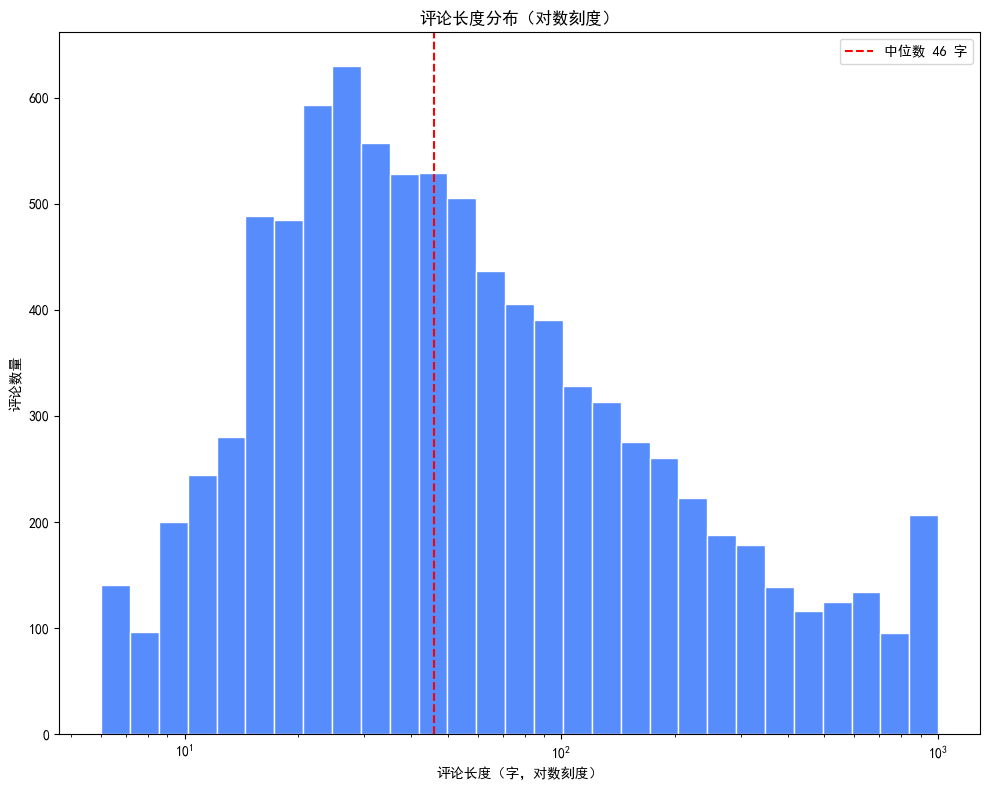

In [28]:
# 6.10评论长度分布：最短 6 字、中位数 46 字、最长 1002 字，长度严重右偏，
comment_len = df_comments_clean['评论内容'].str.len()
bins = np.logspace(np.log10(comment_len.min()), np.log10(comment_len.max()), 30)
plt.figure(figsize=(10, 8))
plt.hist(comment_len, bins=bins, edgecolor='white')
plt.xscale('log')
plt.axvline(comment_len.median(), color='red', linestyle='--', label=f'中位数 {int(comment_len.median())} 字')
plt.xlabel('评论长度（字，对数刻度）')
plt.ylabel('评论数量')
plt.title('评论长度分布（对数刻度）')
plt.legend()
plt.tight_layout()
plt.savefig('../../data/fig/analysis/评论长度分布.png')
plt.show()

# 评论长度分布直方图（对数刻度）

图表信息：横轴评论字数（对数刻度，红色虚线为中位数），纵轴评论数量，数据为清洗后的 9090 条评论。

解读：
1. 评论长度高度右偏：最短 6 字、中位数 46 字、最长 1002 字，71.4% 的评论在 100 字以内，长评论数量很少；
2. 一半的评论落在 23～119 字之间（四分位区间），说明用户大多习惯简短留言，几十字的「有感而发」是评论区的主要形态；
3. 尾部一直延伸到 1000 字附近：超过 500 字的长评论有 556 条（6.1%），其中近 50 条在 990 字以上（接近 B 站 1000 字的输入上限）。这部分长评论数量虽少，但信息量高，是情感分析里信息最丰富的样本；
4. 极个别评论疑似被上游接口截断（例如 1 条 90 字的评论以「这个时代真是」突然结束），对整体分布的影响可以忽略，但说明长度尾部不宜当作完全精确的用户书写长度。